<a href="https://colab.research.google.com/github/Vishnu0918/Python_AI/blob/main/Movie_Dataset_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import kagglehub
import os
path = kagglehub.dataset_download("tmdb/tmdb-movie-metadata")

In [ ]:
#df=pd.read_csv('/kaggle/input/tmdb-movie-metadata/tmdb_5000_movies.csv')
df = pd.read_csv(os.path.join(path, "tmdb_5000_movies.csv"))
df.info()

In [190]:
top_movies = df[
    (df['vote_average'] > 8.0) &
    (df['vote_count'] >= 100)
].sort_values(
    by='vote_average',
    ascending=False
)

top_movies[['title', 'vote_average', 'vote_count']].head(10)

,title,vote_average,vote_count
1881,The Shawshank Redemption,8.5,8205
3337,The Godfather,8.4,5893
2294,Spirited Away,8.3,3840
1818,Schindler's List,8.3,4329
662,Fight Club,8.3,9413
3232,Pulp Fiction,8.3,8428
3865,Whiplash,8.3,4254
2731,The Godfather: Part II,8.3,3338
65,The Dark Knight,8.2,12002
4602,12 Angry Men,8.2,2078


In [ ]:
df['year']=pd.to_numeric(df['release_date'].str[:4], errors='coerce')

In [ ]:
revenue_by_year=df.groupby('year')['revenue'].mean()

In [ ]:
import matplotlib.pyplot as plt

plt.plot(revenue_by_year)
plt.title("Average Movie Revenue by Year")
plt.xlabel('year')
plt.ylabel('Revenue')
plt.show()

In [ ]:
import json
df['genres']=df["genres"].apply(json.loads)

In [ ]:
df['genre_names'] = df['genres'].apply(lambda x: [d['name'] for d in x])


In [ ]:
genre_counts=df['genre_names'].explode().value_counts()

genre_counts.plot(kind='bar')
#plt.plot(genre_counts,kind='bar')

plt.show()

In [ ]:
genres = df['genre_names'].explode()

In [ ]:
exploded=df.explode('genre_names')
exploded = exploded.dropna(
    subset=['year', 'genre_names', 'revenue', 'vote_average'])
genre_rating= exploded.groupby(by='genre_names')['vote_average'].mean()

In [ ]:
df['production_companies']=df['production_companies'].apply(json.loads)
df['production_name']=df['production_companies'].apply(lambda x:[d['name'] for d in x])

In [ ]:
count_movie=df.explode('production_name')
count_movie.groupby(by='production_name')['revenue'].sum().sort_values()

Warner Bros has generated higher cumulative movie revenue than Walt Disney in this dataset.

In [ ]:
credits_df = pd.read_csv(os.path.join(path, "tmdb_5000_credits.csv"))

In [ ]:
credits_df['crew'] = credits_df['crew'].apply(json.loads)

In [ ]:
def get_name(crew):
  for i in crew:
    if i['job'] == 'Director':
      return i['name']
  return None

In [ ]:
credits_df['director']=credits_df['crew'].apply(get_name)

In [ ]:
df2 = df.merge(
    credits_df,
    left_on='id',
    right_on='movie_id',
    how='inner'
)

In [ ]:
df2['director'].value_counts()

In [ ]:
#df2.groupby(by='director')['vote_average'].mean().sort_values()
#df2.groupby(by='director')['vote_average'].max().sort_values()
df2.groupby(by='director')['revenue'].sum().sort_values()


In [191]:
print(df2.shape)
print(df2['director'].isna().sum())

(4803, 28)
30


In [ ]:
# Top 10 directors by movie count
#df2['director'].value_counts().head(10)

# Top 10 directors by average rating
#df2.groupby('director')['vote_average'].mean().sort_values(ascending=False).head(10)

# Top 10 directors by total revenue
df2.groupby('director')['revenue'].sum().sort_values(ascending=False).head(10)

In [ ]:
valid = df[(df['budget'] > 0) & (df['revenue'] > 0)]

print(valid[['budget', 'revenue']].corr())

In [ ]:
b=valid[['budget', 'revenue', 'vote_average']].corr()

In [ ]:
plt.figure(figsize=(25,9))
plt.scatter(valid['budget']/1000,valid['revenue'],alpha=0.5,s=20)

plt.title("Rvenue vs Budget")
plt.xlabel("budget (Thousands)")
plt.ylabel("revenue (Billions)")
plt.show()

Movies with higher budgets tend to generate higher revenues. The positive correlation of approximately 0.705 indicates a moderately strong linear relationship, but it does not prove that higher budgets cause higher revenue.

In [ ]:
plt.imshow(b, vmin=-1, vmax=1)
plt.xticks(range(len(b.columns)), b.columns, rotation=45)
plt.yticks(range(len(b.index)), b.index)
plt.colorbar(label='Correlation')
plt.title('Movie Correlation Matrix')
plt.tight_layout()
plt.show()

In [ ]:
director_revenue=df2.groupby(by='director')['revenue'].sum()
director_revenue=director_revenue.sort_values(ascending=False).head(10)

director_revenue.plot(kind='bar', figsize=(10,9))
plt.title('Top 10 Directors By Revenue')
plt.xlabel('Director')
plt.ylabel('Revenue')
plt.tight_layout()
plt.show()


In [ ]:
genre_rating=exploded.groupby(by='genre_names')['vote_average'].mean()
genre_rating=genre_rating.sort_values(ascending=False)
genre_rating.plot(kind='bar', figsize=(10,9))
plt.title('Average Rating by Genre')
plt.xlabel("Genres")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()

In [ ]:
revenue_by_genre=exploded.groupby(by='genre_names')['revenue'].sum()
revenue_by_genre=revenue_by_genre.sort_values(ascending=False)
revenue_by_genre.plot(kind='bar')
plt.title("Revenue by Genre")
plt.xlabel("Genre")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

War and Drama genres have relatively high average ratings, while Action and Adventure genres generate higher cumulative revenue.

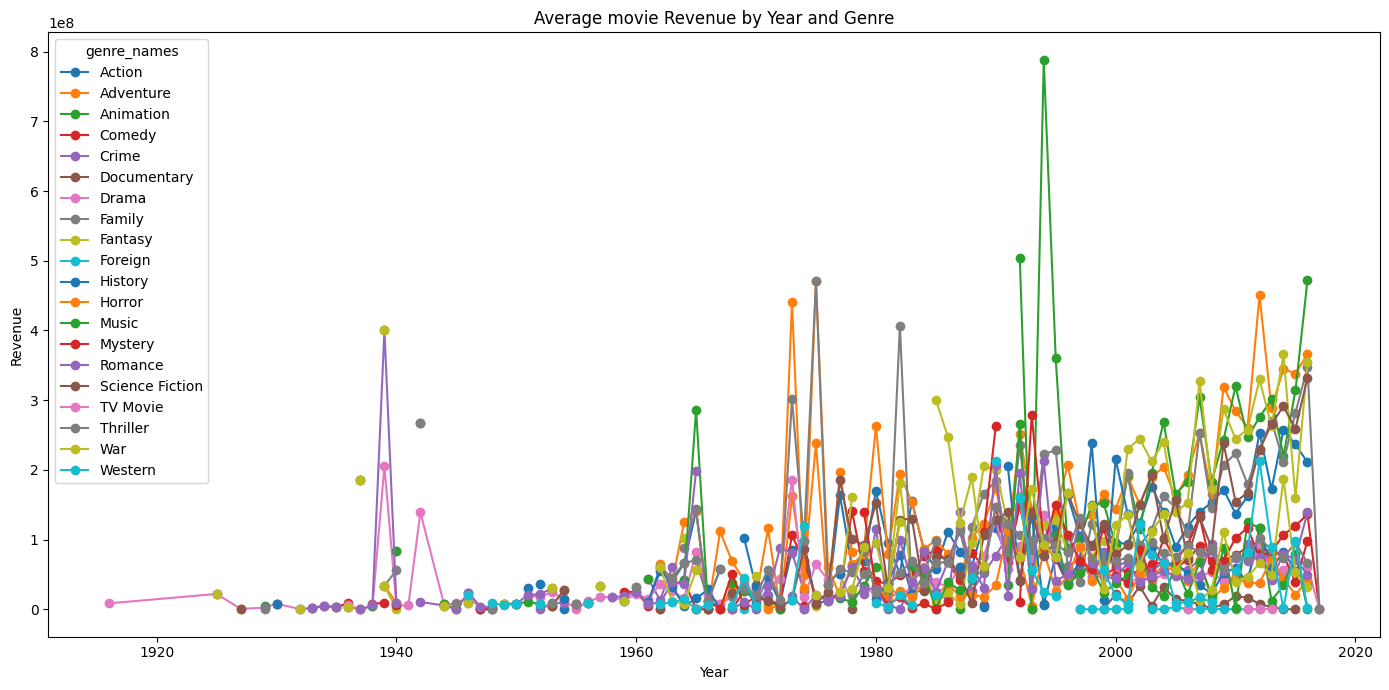

In [189]:
exploded=exploded.dropna(subset=['year','genre_names','revenue'])
exploded=exploded.sort_values(by='year')

v=exploded.pivot_table(index='year',columns='genre_names',values='revenue',aggfunc='mean').sort_index()

v.plot(kind='line', marker="o", figsize=(14,7))
plt.title("Average movie Revenue by Year and Genre")
plt.xlabel('Year')
plt.ylabel('Revenue')
plt.tight_layout()
plt.show()
